[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/06-nlp-and-transformers/notebooks/01-tokens-and-embeddings.ipynb)

# 01 - Tokens and embeddings

**Goal:** see exactly how real models cut text into **tokens** (small pieces of text), turn them into **token IDs** (numbers), and how **embeddings** (lists of numbers that carry meaning) let us compare sentences.

Runs on a normal CPU in a couple of minutes. No API keys needed. The first run downloads a few small files from the Hugging Face Hub.

## Setup
This cell installs any missing package. On Colab and in the course environment everything is usually already there, so it finishes instantly.

In [1]:
import importlib.util, subprocess, sys
# Install a package only if it is missing (Colab already has most of these).
for pkg, mod in [("transformers", "transformers"), ("sentence-transformers", "sentence_transformers"),
                 ("tiktoken", "tiktoken"), ("torch", "torch")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
print("Packages ready")

Packages ready


## 1. A tokenizer from Hugging Face

`AutoTokenizer.from_pretrained(name)` downloads the tokenizer that belongs to a model. We start with GPT-2's tokenizer, which uses **BPE (Byte-Pair Encoding)** — a recipe that builds a vocabulary of common sub-word pieces.

- `tokenize(text)` shows the text pieces.
- `tok(text)["input_ids"]` shows the numbers the model really receives.

In [2]:
from transformers import AutoTokenizer

text = "Tokenization isn't magic: unbelievably, ChatGPT reads tokens!"
gpt2_tok = AutoTokenizer.from_pretrained("gpt2")      # downloads once, then cached
print("Tokens:", gpt2_tok.tokenize(text))
print("IDs:   ", gpt2_tok(text)["input_ids"])
print("Vocabulary size:", gpt2_tok.vocab_size)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tokens: ['Token', 'ization', 'Ġisn', "'t", 'Ġmagic', ':', 'Ġunbelievably', ',', 'ĠChat', 'G', 'PT', 'Ġreads', 'Ġtokens', '!']
IDs:    [30642, 1634, 2125, 470, 5536, 25, 48943, 11, 24101, 38, 11571, 9743, 16326, 0]
Vocabulary size: 50257


**What to notice:** `Ġ` is GPT-2's way of drawing "a space comes before this token". The space belongs to the token. Common words (`magic`, `reads`) are one token; `Tokenization` is two.

## 2. Compare tokenizers

Different models use different vocabularies. BERT uses **WordPiece** (pieces glued to the previous one start with `##`) and lower-cases everything. SmolLM2 uses its own BPE vocab.

In [3]:
for name in ["bert-base-uncased", "gpt2", "HuggingFaceTB/SmolLM2-135M-Instruct"]:
    tok = AutoTokenizer.from_pretrained(name)
    pieces = tok.tokenize(text)
    print(f"{name:<40} {len(pieces):>2} tokens: {pieces}")

bert-base-uncased                        20 tokens: ['token', '##ization', 'isn', "'", 't', 'magic', ':', 'un', '##bel', '##ie', '##va', '##bly', ',', 'chat', '##gp', '##t', 'reads', 'token', '##s', '!']


gpt2                                     14 tokens: ['Token', 'ization', 'Ġisn', "'t", 'Ġmagic', ':', 'Ġunbelievably', ',', 'ĠChat', 'G', 'PT', 'Ġreads', 'Ġtokens', '!']


HuggingFaceTB/SmolLM2-135M-Instruct      15 tokens: ['Token', 'ization', 'Ġisn', "'t", 'Ġmagic', ':', 'Ġunbelie', 'v', 'ably', ',', 'ĠChat', 'GPT', 'Ġreads', 'Ġtokens', '!']


## 3. tiktoken — OpenAI's tokenizer

**tiktoken** is a fast tokenizer library from OpenAI. An **encoding** is one vocabulary plus its merge rules. `cl100k_base` (about 100k tokens) and `o200k_base` (about 200k tokens) are two of them. Bigger vocabularies usually need fewer tokens for the same text.

In [4]:
import tiktoken

for enc_name in ["cl100k_base", "o200k_base"]:
    enc = tiktoken.get_encoding(enc_name)
    ids = enc.encode(text)
    print(f"{enc_name}: {len(ids)} tokens")
    print("   pieces:", [enc.decode([i]) for i in ids])
    print("   decode(encode(text)) == text ->", enc.decode(ids) == text)

cl100k_base: 15 tokens
   pieces: ['Token', 'ization', ' isn', "'t", ' magic', ':', ' unbelie', 'vably', ',', ' Chat', 'G', 'PT', ' reads', ' tokens', '!']
   decode(encode(text)) == text -> True


o200k_base: 12 tokens
   pieces: ['Token', 'ization', " isn't", ' magic', ':', ' unbelievably', ',', ' Chat', 'GPT', ' reads', ' tokens', '!']
   decode(encode(text)) == text -> True


## 4. Tokens per word in different kinds of text

Pricing and limits are counted in **tokens**, not words. Let's measure how many tokens different texts need. Code, numbers and non-English text often need more tokens per word.

In [5]:
enc = tiktoken.get_encoding("o200k_base")
samples = {
    "plain English": "The weather in Hyderabad is warm and sunny today.",
    "Python code":   "for i in range(10): print(i ** 2)",
    "long number":   "Order 8473629104 costs 12345.67 rupees",
    "Hindi":         "आज हैदराबाद में मौसम गर्म और धूप वाला है।",
    "rare words":    "Pneumonoultramicroscopicsilicovolcanoconiosis is a word.",
}
for label, s in samples.items():
    n_tok, n_words = len(enc.encode(s)), len(s.split())
    print(f"{label:<14} words={n_words:>2}  tokens={n_tok:>2}  tokens/word={n_tok / n_words:.2f}")

plain English  words= 9  tokens=10  tokens/word=1.11
Python code    words= 7  tokens=13  tokens/word=1.86
long number    words= 5  tokens=14  tokens/word=2.80
Hindi          words= 9  tokens=14  tokens/word=1.56
rare words     words= 4  tokens=19  tokens/word=4.75


**Rule of thumb:** for English, 1 token is about 4 characters or 0.75 words. Always measure for your own text.

## 5. Embeddings: meaning as numbers

An **embedding** is a vector (a list of numbers). `sentence-transformers/all-MiniLM-L6-v2` turns any sentence into 384 numbers, trained so that sentences with similar meaning get similar vectors.

In [6]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
sentences = [
    "How do I reset my password?",
    "I forgot my login details.",
    "The cat is sleeping on the sofa.",
    "A kitten naps on the couch.",
    "What is the price of the premium plan?",
    "How much does the subscription cost?",
]
vectors = embedder.encode(sentences)
print("Shape:", vectors.shape, "-> 6 sentences x 384 numbers")
print("First 8 numbers of sentence 0:", vectors[0][:8].round(3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9492.92it/s]

Shape: (6, 384) -> 6 sentences x 384 numbers
First 8 numbers of sentence 0: [ 0.007 -0.063 -0.072 -0.032 -0.043  0.07   0.009  0.015]


## 6. Cosine similarity by hand

**Cosine similarity** measures whether two vectors point the same way: 1 = same direction, 0 = unrelated, -1 = opposite. Formula: dot product divided by (length of a × length of b). We write it ourselves first, then check against the library.

In [7]:
import numpy as np

def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

print("password vs login :", round(cosine(vectors[0], vectors[1]), 3))
print("password vs kitten:", round(cosine(vectors[0], vectors[3]), 3))
print("cat vs kitten     :", round(cosine(vectors[2], vectors[3]), 3))

from sentence_transformers import util
print("library check     :", round(float(util.cos_sim(vectors[2], vectors[3])), 3))

password vs login : 0.541
password vs kitten: -0.022
cat vs kitten     : 0.698
library check     : 0.698


## 7. The full similarity grid as a heatmap
A **heatmap** colours each cell of a table by its value. Bright squares off the diagonal show pairs with similar meaning.

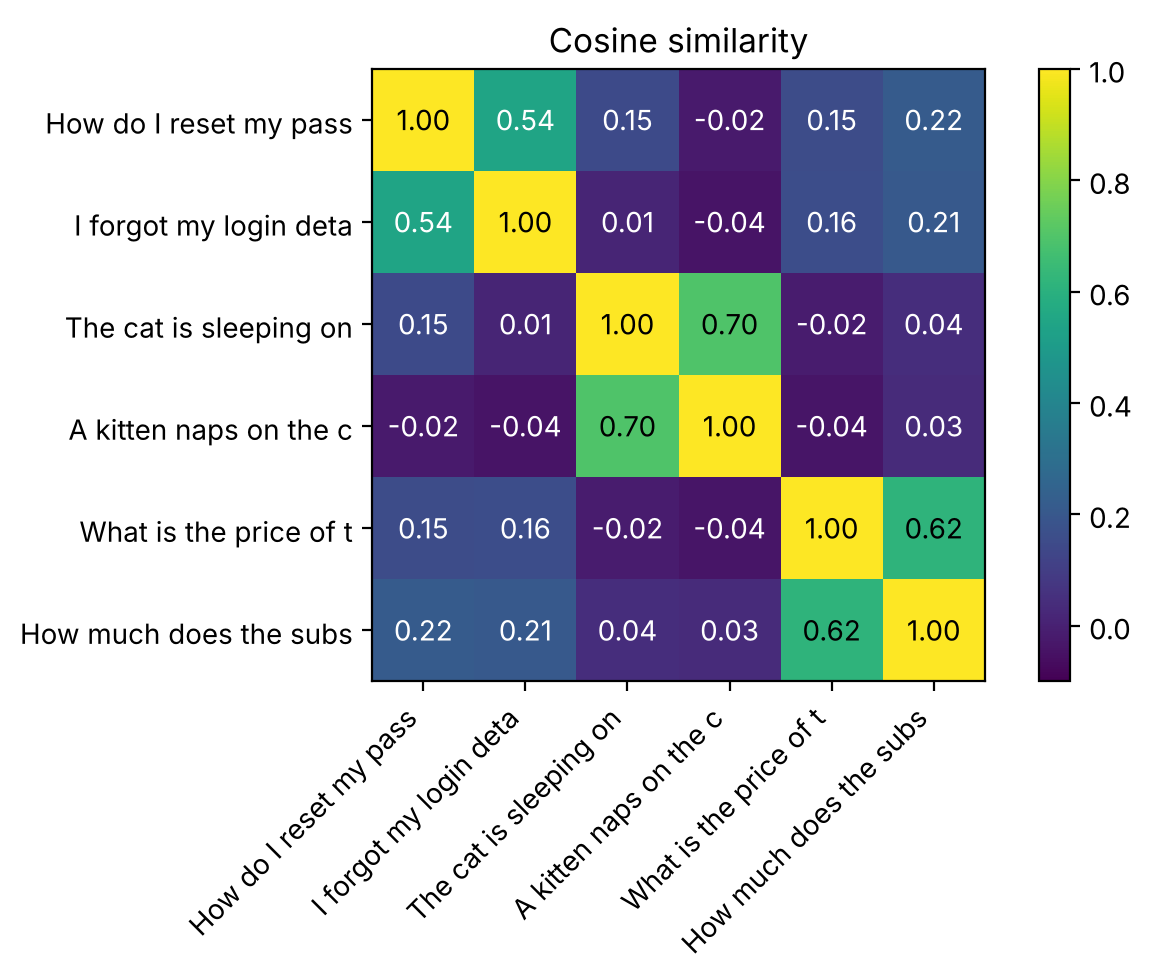

In [8]:
import matplotlib.pyplot as plt

sim = np.array([[cosine(a, b) for b in vectors] for a in vectors])
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(sim, cmap="viridis", vmin=-0.1, vmax=1)
labels = [s[:22] for s in sentences]
ax.set_xticks(range(6), labels=labels, rotation=45, ha="right")
ax.set_yticks(range(6), labels=labels)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", color="white" if sim[i, j] < 0.6 else "black")
fig.colorbar(im)
ax.set_title("Cosine similarity")
plt.tight_layout()
plt.show()

## 8. A tiny semantic search engine

**Semantic search** finds text by meaning, not by matching words. Embed the question, score every stored sentence, return the best. This is the core of RAG (Module 09).

In [9]:
def search(query, k=2):
    q = embedder.encode(query)
    scores = [cosine(q, v) for v in vectors]
    best = np.argsort(scores)[::-1][:k]          # indices of the k highest scores
    return [(sentences[i], round(scores[i], 3)) for i in best]

for q in ["I can't remember my password", "is there a monthly fee?", "pets resting"]:
    print(q, "->", search(q))

I can't remember my password -> [('How do I reset my password?', 0.828), ('I forgot my login details.', 0.571)]
is there a monthly fee? -> [('How much does the subscription cost?', 0.622), ('What is the price of the premium plan?', 0.476)]
pets resting -> [('A kitten naps on the couch.', 0.395), ('The cat is sleeping on the sofa.', 0.238)]


## Try it yourself
1. Add your own sentence in another language you know to `samples` and compare tokens per word.
2. Add two sentences that mean the same thing but share no words. Does MiniLM score them high?
3. Search for something with no good match. What scores come back? (Hint: there is always a "best" result, even when it is bad — real systems use a minimum score.)